# CompBench Agent Evaluation

Runs the MMEdit agent over the full CompBench annotation set. Shared JSONL/Hugging Face image loading, reference preparation, agent execution, and debug capture live in `evaluation/common.py`.

Install with `uv sync --extra models --extra benchmark`. This notebook reads generated annotations from `.out/annotation/compbench/compbench_local_multiobject_mixed.jsonl`; run the CompBench annotation notebook first. Set `MMEDIT_COMPBENCH_ANNOTATIONS` only to override that file. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`. The run cell processes all annotations; use `compbench_debug.ipynb` for a representative sample from each task. HF image references use original split row indices.

In [1]:
import matplotlib.pyplot as plt
from evaluation.notebook import create_run_directory, load_benchmark
from evaluation.common import annotate_sample, load_sample, run_benchmark, select_reference_prompts

BENCHMARK = "compbench"
RANDOM_SEED = 42
context = load_benchmark(BENCHMARK)
ANNOTATION_FILE = context.annotation_file
OUTPUT_ROOT = context.output_dir
records = context.records
image_loader = context.image_loader
print(f"{len(records)} CompBench annotations loaded from {ANNOTATION_FILE}")
print("Fields:", sorted(records[0]))

2609 CompBench annotations loaded from /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/annotation/compbench/compbench_local_multiobject_mixed.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


add:001ca3cb/0/00003.png add a gray fish on <v1> with its head downward
Reference selectors: [{'token': '<v1>', 'refers_to': 'the leftmost', 'box': [0, 50, 282, 428], 'point': [100.5, 369.5], 'scribble': True}]


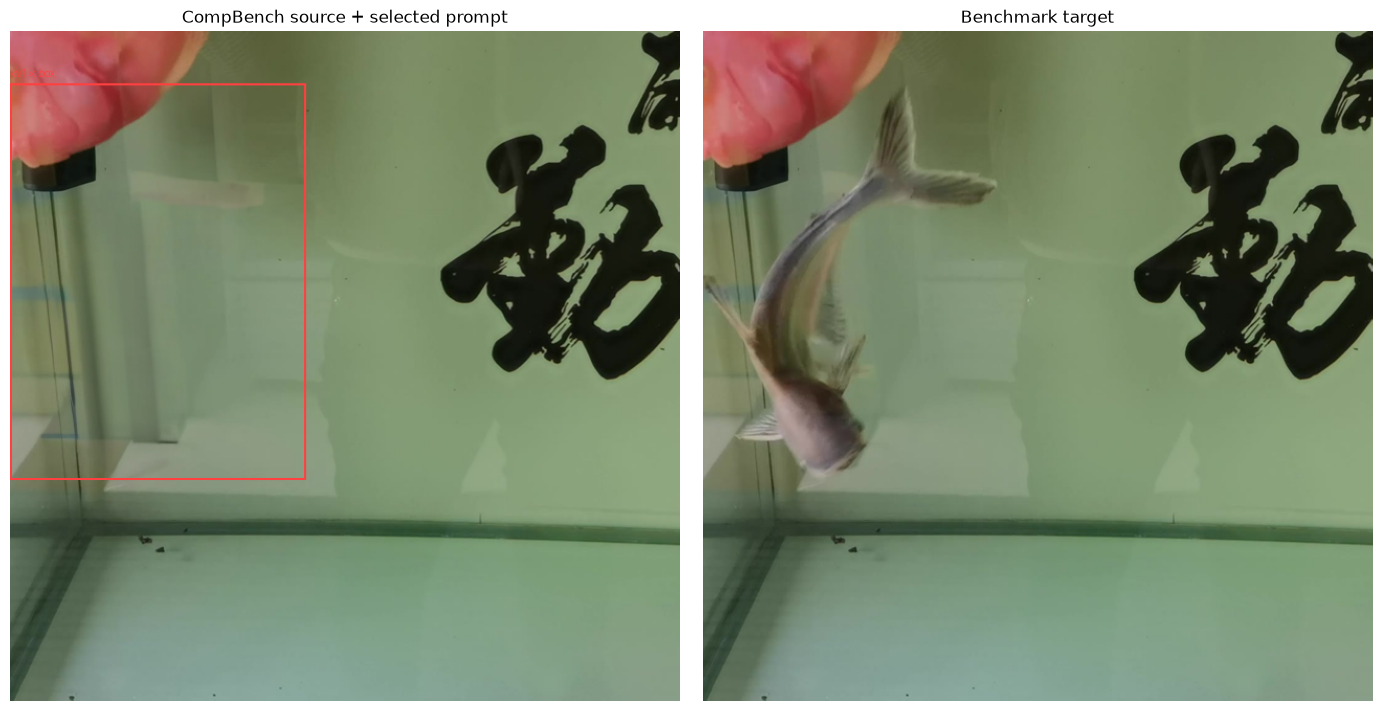

In [2]:
SAMPLE_INDEX = 0
record = records[SAMPLE_INDEX]
sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader)
if not sample["instruction"]:
    raise ValueError("CompBench record has no instruction.")
print(sample["sample_id"], sample["instruction"])
print("Reference selectors:", [
    {
        "token": reference["token"],
        "refers_to": reference["span"],
        "box": reference["bbox_xyxy"],
        "point": reference["point_xy"],
        "scribble": bool(reference["scribble_strokes"]),
    }
    for reference in sample["references"]
])
select_reference_prompts(sample, seed=RANDOM_SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(annotate_sample(sample))
axes[0].set_title("CompBench source + selected prompt")
axes[0].axis("off")
if sample["target_image"] is None:
    axes[1].text(0.5, 0.5, "No target image", ha="center", va="center")
else:
    axes[1].imshow(sample["target_image"])
axes[1].set_title("Benchmark target")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [3]:
from framework.tools import image_editing_tools
from evaluation.notebook import create_agent_model

llm = create_agent_model()
tools = image_editing_tools()
print("CompBench agent ready:", llm.model_id)

CompBench agent ready: gemini-3.5-flash


In [4]:
# Annotation indices refer to the JSONL order; hf:// image refs retain original dataset row indices.
SAMPLE_INDICES = range(len(records))
RUN_DIR = create_run_directory(OUTPUT_ROOT)
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    output_dir=RUN_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    seed=RANDOM_SEED,
    display_fn=None,
)
print("Run directory:", RUN_DIR)
print(f"Processed {len(benchmark_results)} CompBench samples.")

compbench inference:   0%|          | 0/2609 [00:00<?, ?sample/s]

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `vae_scale_factor` directly via 'Flux2ImageProcessor' object attribute is deprecated. Please access 'vae_scale_factor' over 'Flux2ImageProcessor's config object instead, e.g. 'scheduler.config.vae_scale_factor'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


...

Error in generating model output:
Error code: 402 - [{'error': {'code': 402, 'message': 'Your prepayment credits are depleted. Please go to AI Studio
at https://ai.studio/projects to manage your project and billing. Learn more at 
https://ai.google.dev/gemini-api/docs/billing#prepay. ', 'status': 'RESOURCE_EXHAUSTED'}}]

Error in generating model output:
Error code: 402 - [{'error': {'code': 402, 'message': 'Your prepayment credits are depleted. Please go to AI Studio
at https://ai.studio/projects to manage your project and billing. Learn more at 
https://ai.google.dev/gemini-api/docs/billing#prepay. ', 'status': 'RESOURCE_EXHAUSTED'}}]

Error in generating model output:
Error code: 402 - [{'error': {'code': 402, 'message': 'Your prepayment credits are depleted. Please go to AI Studio
at https://ai.studio/projects to manage your project and billing. Learn more at 
https://ai.google.dev/gemini-api/docs/billing#prepay. ', 'status': 'RESOURCE_EXHAUSTED'}}]

Error in generating model output:
Error code: 402 - [{'error': {'code': 402, 'message': 'Your prepayment credits are depleted. Please go to AI Studio
at https://ai.studio/projects to manage your project and billing. Learn more at 
https://ai.google.dev/gemini-api/docs/billing#prepay. ', 'status': 'RESOURCE_EXHAUSTED'}}]

KeyboardInterrupt: 

In [ ]:
completed = [result for result in benchmark_results if result["status"] == "completed"]
failed = [result for result in benchmark_results if result["status"] == "failed"]
print(
    f"CompBench samples: {len(benchmark_results)} | "
    f"completed: {len(completed)} | failed: {len(failed)}"
)
if benchmark_results:
    mean_runtime = sum(result["elapsed_seconds"] for result in benchmark_results) / len(benchmark_results)
    print(f"Mean runtime: {mean_runtime:.2f}s")
print("Compare saved outputs with the benchmark targets; image-quality scoring is separate.")